In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib as mpl

In [3]:
df = pd.read_csv('../data/mock_df_one_flight.csv')
df.head()

,_t,acceleration_x,acceleration_y,acceleration_z,rotation_x,rotation_y,rotation_z,magnetic_x,magnetic_y,magnetic_z,...,magnetic_down,vario,vario_average,vario_pressure,vario_uncompensated,speed_compensation_tas,speed_compensation_ins,system_state,voltage,dummy_for_data_alignment
0,0.00,0.0272,-0.0305,9.7570,0.00000,0.00000,0.00000,21.41,1.90,42.97,...,43.1,-0.261,-0.222,0.291,0.063,0.000,0.0,FLIGHT,12.4,0
1,0.01,-0.0374,-0.0063,9.7762,0.00001,0.00001,0.00001,21.60,1.96,43.11,...,43.1,-0.293,-0.249,-0.101,-0.037,10.321,0.0,FLIGHT,12.4,0
2,0.02,-0.0230,0.0021,9.7173,0.00002,0.00001,0.00002,21.45,1.69,42.93,...,43.1,0.220,0.187,0.227,0.572,10.321,0.0,FLIGHT,12.4,0
3,0.03,-0.0433,-0.0285,9.7194,0.00004,0.00002,0.00003,21.45,1.67,43.06,...,43.1,0.440,0.374,0.148,0.279,10.320,0.0,FLIGHT,12.4,0
4,0.04,0.0069,-0.0032,9.7106,0.00005,0.00003,0.00004,21.32,1.81,43.25,...,43.1,-0.463,-0.393,0.036,0.076,10.319,0.0,FLIGHT,12.4,0


In [4]:
df.columns

Index(['_t', 'acceleration_x', 'acceleration_y', 'acceleration_z',
       'rotation_x', 'rotation_y', 'rotation_z', 'magnetic_x', 'magnetic_y',
       'magnetic_z', 'pitot', 'static_pressure', 'temperature_pcb', 'latitude',
       'longitude', 'position_up', 'position_down', 'velocity_north',
       'velocity_east', 'velocity_down', 'speed_accuracy', 'sat_count',
       'sat_fix_type', 'geo_separation', 'pos_dilution_of_precision',
       'relpos_north', 'relpos_east', 'relpos_down', 'rel_heading', 'year',
       'month', 'day', 'hour', 'minute', 'second', 'nanoseconds', 'ias', 'tas',
       'speed_ground', 'track_ground', 'wind_north', 'wind_east', 'wind_down',
       'wind_average_north', 'wind_average_east', 'wind_average_down',
       'circle_mode', 'q0', 'q1', 'q2', 'q3', 'roll_angle', 'pitch_angle',
       'yaw_angle', 'effective_acceleration_vertical', 'turn_rate',
       'slip_angle', 'apparent_pitch_angle', 'g_load', 'pressure_altitude',
       'air_density', 'magnetic_disturb

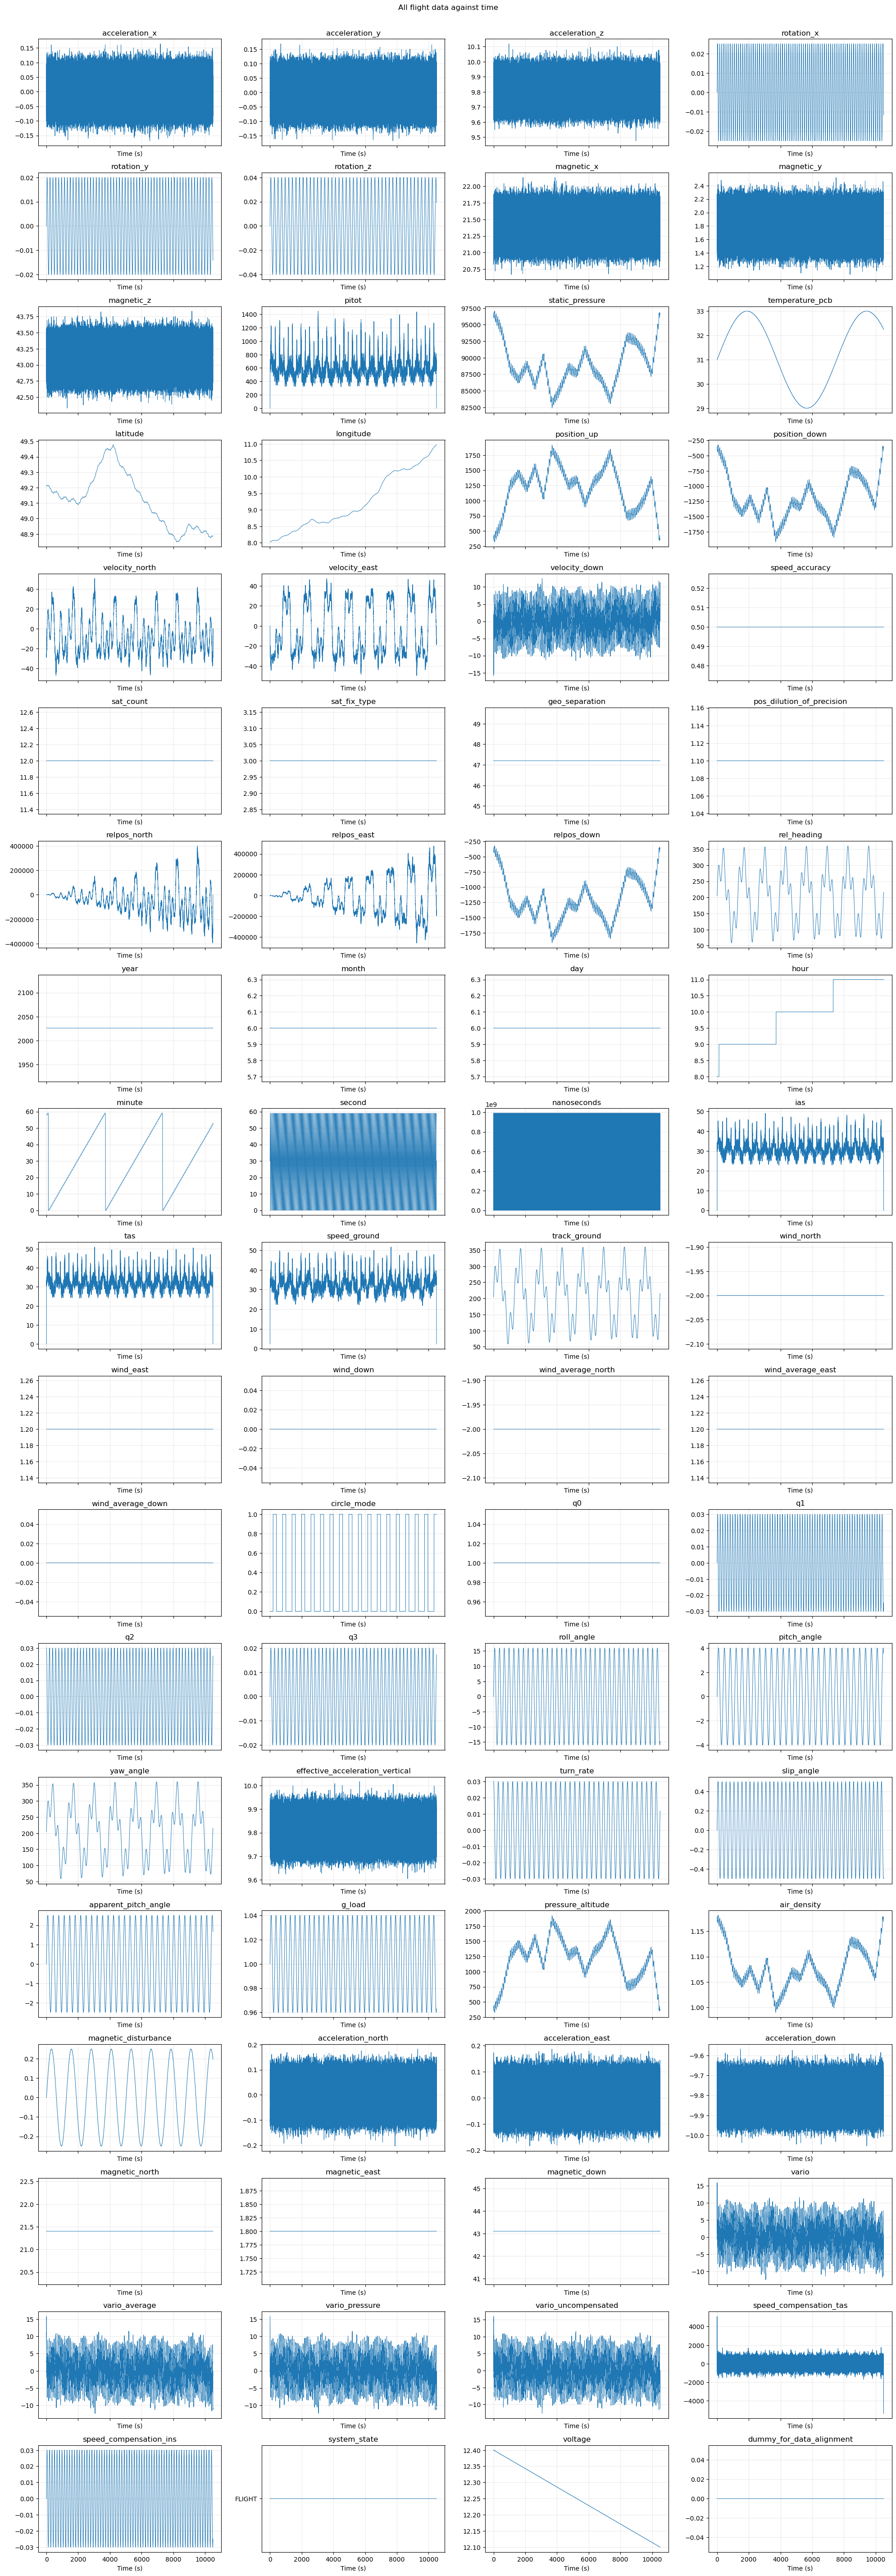

In [5]:
# Plot each flight data column against elapsed time (_t), one subplot per column.
time_col = '_t'
data_cols = [col for col in df.columns if col != time_col]
ncols = 4
nrows = int(np.ceil(len(data_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 3 * nrows), sharex=True)
axes = np.asarray(axes).reshape(-1)

for ax, col in zip(axes, data_cols):
    values = df[col]
    if pd.api.types.is_numeric_dtype(values):
        ax.plot(df[time_col], values, linewidth=0.7)
    else:
        codes, categories = pd.factorize(values, sort=True)
        ax.step(df[time_col], codes, where='post', linewidth=0.7)
        ax.set_yticks(range(len(categories)), labels=categories)
    ax.set_title(col)
    ax.set_xlabel('Time (s)')
    ax.grid(True, alpha=0.25)

for ax in axes[len(data_cols):]:
    ax.set_visible(False)

fig.suptitle('All flight data against time', y=1.002)
fig.tight_layout()
plt.show()